# 07 · Model evaluation: which trait matters for which outcome?
**DS 5110 Big Data Systems — Final Project: Trench Play (OL and DL)**

**What this notebook does**
1. Scores every tuned model from notebook 06 on **validation** (2023–24 players held out) and **test** (the whole 2025 class, never used for training or tuning).
2. **Metrics.** Classification: AUROC with a 95% **player-bootstrap** CI, AUPR, and accuracy / precision / recall / F1 at a threshold chosen on validation (max F1), plus top-decile lift. Regression: R², RMSE, MAE at the snap level, and R² of player averages (30+ snaps).
3. **Ceiling ("oracle").** Context plus each player's *actual* average outcome on the scored split. It leaks on purpose and shows the most any player trait could add.
4. **Trait effects (the research question).** For first-step quickness, lateral agility and burst, separately and together, plus the stopwatch equivalent: the change in test metric over the context-only benchmark, with a **paired player-bootstrap 95% CI**. Also the **direction** of each trait's standardized coefficient, oriented so that + means "better trait → better line play".
5. **Champion** per task, chosen on validation: confusion matrix (classification), hyperparameter **sensitivity**, and feature-importance shares by block.
6. **Player-level ranking**: do the models order the 2025 rookies correctly?

**Inputs:** `processed/task_*.parquet`, `outputs/models/*`, `outputs/tables/06_*.csv`.  **Outputs:** `outputs/tables/07_*.csv`, `outputs/figures/07_*.png`.

In [1]:
import sys, json, os
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import functions as F
from pyspark.sql.window import Window
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.functions import vector_to_array
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.regression import LinearRegression
import config as C

spark = C.get_spark("07_eval")
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
FS = json.load(open(C.OUTPUT_DIR / "feature_sets.json"))
cv_sum = pd.read_csv(C.TABLE_DIR / "06_cv_summary.csv")
cv_res = pd.read_csv(C.TABLE_DIR / "06_cv_results.csv")
TASKS = [t for t in FS["tasks"] if t in set(cv_sum.task)]
MODELS = ["benchmark", "first_step", "lateral", "burst", "traits", "stopwatch", "traits_size", "rf", "gbt"]
LABEL = {"benchmark": "Benchmark (context only)", "first_step": "+ first-step quickness", "lateral": "+ lateral agility",
         "burst": "+ burst", "traits": "+ all three traits", "stopwatch": "+ stopwatch equivalents",
         "traits_size": "+ traits, stopwatch, size", "rf": "Random forest (all)", "gbt": "GBT (all)", "oracle": "Ceiling: + player's true average"}
TASK_LABEL = {"dl_pressure": "DL pass rush: pressure", "dl_getoff": "DL pass rush: get-off time",
              "ol_pressure": "OL pass block: pressure allowed", "ol_pressure_prob": "OL pass block: peak pressure prob.",
              "ol_run": "OL run block: run success at his gap"}
# + = better line play: DL want pressure (+) and a low get-off; OL want low pressure; run success (+)
GOOD_DIR = {"dl_pressure": 1, "dl_getoff": -1, "ol_pressure": -1, "ol_pressure_prob": -1, "ol_run": 1}
rng = np.random.default_rng(C.SEED)
B = int(os.environ.get("N_BOOT", "300"))

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


/apps/software/standard/core/spark/4.2.0/python/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/11/25 21:54:17 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


## 1. Score every model on validation and test

In [2]:
def score(model, df, kind):
    out = model.transform(df)
    pred = vector_to_array("probability")[1] if kind == "classification" else F.col("prediction")
    return out.select("nfl_id", "target", pred.alias("p")).toPandas()

preds, data = {}, {}
for task in TASKS:
    kind = FS["tasks"][task]["kind"]
    d = spark.read.parquet(C.p(f"task_{task}.parquet"))
    data[task] = d
    for split in ("validation", "test"):
        part = d.filter(F.col("split") == split).cache()
        for m in MODELS:
            if (C.MODEL_DIR / task / m).exists():
                preds[(task, m, split)] = score(PipelineModel.load(str(C.MODEL_DIR / task / m)), part, kind)
    print(task, "scored")

/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


... (85 outputs left out)

/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


ol_run scored


/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


### Ceiling ("oracle") per task
Context features plus the player's actual average outcome on the split being scored. Not a usable model: it only marks how much room player traits could possibly have.

In [3]:
def oracle_pipe(task, kind):
    cats = FS["context_cat"] + (FS["run_cat"] if task == "ol_run" else [])
    nums = FS["context_num"] + (FS["run_num"] if task == "ol_run" else []) + ["player_mean"]
    est = (LogisticRegression(featuresCol="features", labelCol="target", weightCol="weight", regParam=0.01) if kind == "classification"
           else LinearRegression(featuresCol="features", labelCol="target", weightCol="weight", regParam=0.01))
    return Pipeline(stages=[StringIndexer(inputCol=c, outputCol=f"{c}_i", handleInvalid="keep") for c in cats] + [
        OneHotEncoder(inputCols=[f"{c}_i" for c in cats], outputCols=[f"{c}_o" for c in cats], handleInvalid="keep"),
        VectorAssembler(inputCols=[f"{c}_o" for c in cats] + nums, outputCol="fr", handleInvalid="keep"),
        StandardScaler(inputCol="fr", outputCol="features", withMean=True, withStd=True), est])
with_mean = lambda df: df.withColumn("player_mean", F.avg("target").over(Window.partitionBy("nfl_id")))
for task in TASKS:
    kind = FS["tasks"][task]["kind"]; d = data[task]
    om = oracle_pipe(task, kind).fit(with_mean(d.filter("split = 'train'")))
    for split in ("validation", "test"):
        preds[(task, "oracle", split)] = score(om, with_mean(d.filter(F.col("split") == split)), kind)

/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


## 2. Metrics with player-bootstrap confidence intervals

In [4]:
def auc(y, p):
    r = pd.Series(p).rank().values; n1 = y.sum(); n0 = len(y) - n1
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0) if n1 and n0 else np.nan
def aupr(y, p):
    o = np.argsort(-p); ys = y[o]; tp = np.cumsum(ys)
    return (tp / np.arange(1, len(ys) + 1) * ys).sum() / ys.sum()
def r2(y, p):
    return 1 - ((y - p) ** 2).sum() / ((y - y.mean()) ** 2).sum()
def at_thr(y, p, t):
    yh = (p >= t).astype(int); tp = int(((yh == 1) & (y == 1)).sum()); fp = int(((yh == 1) & (y == 0)).sum())
    fn = int(((yh == 0) & (y == 1)).sum()); tn = int(((yh == 0) & (y == 0)).sum())
    pr = tp / (tp + fp) if tp + fp else 0.0; rc = tp / (tp + fn) if tp + fn else 0.0
    return dict(accuracy=(tp + tn) / len(y), precision=pr, recall=rc, f1=2 * pr * rc / (pr + rc) if pr + rc else 0.0, tp=tp, fp=fp, fn=fn, tn=tn)
def best_thr(y, p):
    g = np.quantile(p, np.linspace(0.30, 0.98, 69)); return max(g, key=lambda t: at_thr(y, p, t)["f1"])
def lift10(y, p):
    k = max(1, int(round(0.1 * len(y)))); return y[np.argsort(-p)[:k]].mean() / y.mean()
def player_r2(df, min_n=30):
    g = df.groupby("nfl_id").agg(n=("target", "size"), y=("target", "mean"), p=("p", "mean")); g = g[g.n >= min_n]
    return r2(g.y.values, g.p.values)
metric = lambda kind: auc if kind == "classification" else r2

def boot_ids(df):
    groups = {k: g.index.values for k, g in df.groupby("nfl_id")}; ids = np.array(list(groups))
    return groups, ids
def boot_ci(df, kind, n=B):
    groups, ids = boot_ids(df); f = metric(kind); vals = []
    y, p = df.target.values, df.p.values
    for _ in range(n):
        ix = np.concatenate([groups[i] for i in rng.choice(ids, len(ids), replace=True)])
        vals.append(f(y[ix], p[ix]))
    return np.nanpercentile(vals, [2.5, 97.5])

rows = []
for task in TASKS:
    kind = FS["tasks"][task]["kind"]
    for m in MODELS + ["oracle"]:
        if (task, m, "test") not in preds:
            continue
        v, t = preds[(task, m, "validation")], preds[(task, m, "test")]
        yv, pv, yt, pt = v.target.values, v.p.values, t.target.values, t.p.values
        lo, hi = boot_ci(t, kind)
        row = {"task": task, "kind": kind, "model": m, "label": LABEL[m],
               "cv": cv_sum.set_index(["task", "model"]).cv_mean.get((task, m), np.nan),
               "val": metric(kind)(yv, pv), "test": metric(kind)(yt, pt), "test_ci_lo": lo, "test_ci_hi": hi}
        if kind == "classification":
            thr = best_thr(yv, pv); row.update({"aupr": aupr(yt, pt), "threshold": thr, **{k: at_thr(yt, pt, thr)[k] for k in ["accuracy", "precision", "recall", "f1"]},
                                                "lift_top10": lift10(yt, pt), "base_rate": yt.mean()})
        else:
            row.update({"rmse": float(np.sqrt(((yt - pt) ** 2).mean())), "mae": float(np.abs(yt - pt).mean()), "player_r2": player_r2(t)})
        rows.append(row)
res = pd.DataFrame(rows)
res.round(4).to_csv(C.TABLE_DIR / "07_model_metrics.csv", index=False)
print("test metric = AUROC (classification) or R² (regression)")
res.pivot_table(index="model", columns="task", values="test").reindex(MODELS + ["oracle"]).round(3)

test metric = AUROC (classification) or R² (regression)


task,dl_getoff,dl_pressure,ol_pressure,ol_pressure_prob,ol_run
model,,,,,
benchmark,0.221,0.563,0.577,0.033,0.632
first_step,0.219,0.562,0.577,0.033,0.631
lateral,0.224,0.563,0.576,0.032,0.629
burst,0.227,0.560,0.577,0.033,0.631
traits,0.230,0.563,0.575,0.030,0.626
stopwatch,0.225,0.567,0.577,0.033,0.629
traits_size,0.215,0.544,0.572,0.028,0.619
rf,0.162,0.568,0.579,0.028,0.628
gbt,0.225,0.566,0.562,0.026,0.625


## 3. Trait effects: change over the benchmark, paired player bootstrap
Both models are scored on the **same** resampled players in every bootstrap draw, so the interval reflects the difference itself.

In [5]:
EFFECT_MODELS = ["first_step", "lateral", "burst", "traits", "stopwatch"]
eff = []
for task in TASKS:
    kind = FS["tasks"][task]["kind"]; f = metric(kind)
    base = preds[(task, "benchmark", "test")]
    groups, ids = boot_ids(base)
    draws = [np.concatenate([groups[i] for i in rng.choice(ids, len(ids), replace=True)]) for _ in range(B)]
    y = base.target.values; pb = base.p.values
    for m in EFFECT_MODELS:
        pm = preds[(task, m, "test")].p.values
        diffs = [f(y[ix], pm[ix]) - f(y[ix], pb[ix]) for ix in draws]
        eff.append({"task": task, "model": m, "delta": f(y, pm) - f(y, pb),
                    "ci_lo": np.nanpercentile(diffs, 2.5), "ci_hi": np.nanpercentile(diffs, 97.5)})
eff = pd.DataFrame(eff)
eff["significant"] = (eff.ci_lo > 0) | (eff.ci_hi < 0)
eff.round(4).to_csv(C.TABLE_DIR / "07_trait_effects.csv", index=False)
eff.pivot_table(index="model", columns="task", values="delta").reindex(EFFECT_MODELS).round(4)

task,dl_getoff,dl_pressure,ol_pressure,ol_pressure_prob,ol_run
model,,,,,
first_step,-0.0016,-0.0013,-0.0004,-0.0005,-0.0017
lateral,0.0026,0.0000,-0.0014,-0.0012,-0.0034
burst,0.0063,-0.0030,-0.0002,-0.0004,-0.0014
traits,0.0091,-0.0000,-0.0023,-0.0031,-0.0060
stopwatch,0.0039,0.0041,-0.0002,-0.0009,-0.0033


### Direction of each trait (standardized coefficients in the `traits` model)
Oriented so that **+ = a better Combine trait goes with better line play** (more pressure for DL, a quicker get-off, less pressure allowed, more run success). Magnitudes are per standard deviation of the trait index (log-odds for classification, outcome units for regression).

In [6]:
coef_rows = []
for task in TASKS:
    mdl = PipelineModel.load(str(C.MODEL_DIR / task / "traits"))
    tr = mdl.transform(data[task].limit(5))
    attrs = tr.schema["features_raw"].metadata["ml_attr"]["attrs"]
    names = [a["name"] for a in sorted([a for g in attrs.values() for a in g], key=lambda a: a["idx"])]
    coefs = mdl.stages[-1].coefficients.toArray()
    for tname in FS["trk"]:
        coef_rows.append({"task": task, "trait": tname.replace("trk_", ""), "coef": coefs[names.index(tname)],
                          "oriented": GOOD_DIR[task] * coefs[names.index(tname)]})
coef = pd.DataFrame(coef_rows); coef.round(4).to_csv(C.TABLE_DIR / "07_trait_directions.csv", index=False)
coef.pivot_table(index="trait", columns="task", values="oriented").round(4)

task,dl_getoff,dl_pressure,ol_pressure,ol_pressure_prob,ol_run
trait,,,,,
burst,0.0320,0.0239,0.0431,0.0050,0.0198
first_step,-0.0287,-0.0849,-0.0174,-0.0007,0.0256
lateral,0.0003,-0.0078,0.0509,0.0050,0.0563


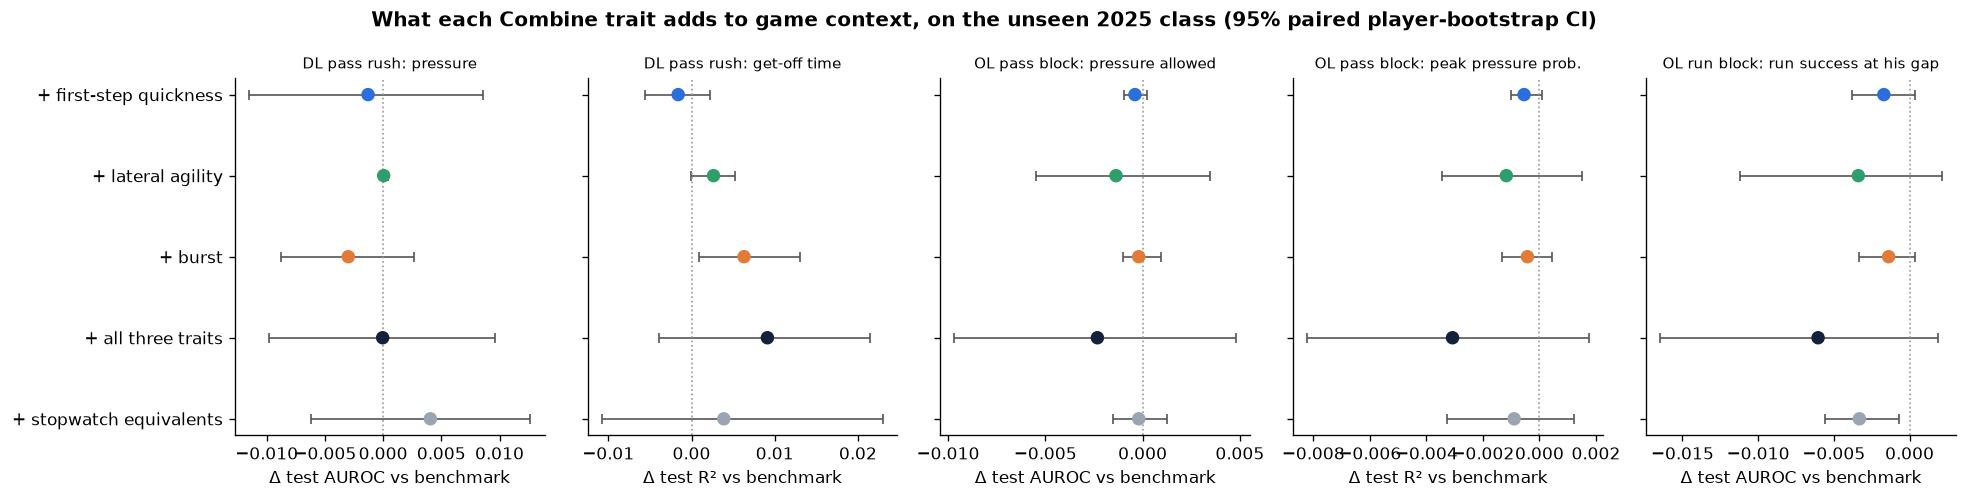

In [7]:
# Headline figure: trait effects per task with paired-bootstrap CIs
fig, axes = plt.subplots(1, len(TASKS), figsize=(3.3 * len(TASKS), 4.2), sharey=True)
cols = {"first_step": "#2a6fdb", "lateral": "#2e9e6b", "burst": "#e07b39", "traits": "#14213D", "stopwatch": "#9aa5b1"}
for ax, task in zip(np.atleast_1d(axes), TASKS):
    d = eff[eff.task == task].set_index("model").reindex(EFFECT_MODELS)
    ypos = np.arange(len(d))[::-1]
    ax.errorbar(d.delta, ypos, xerr=[d.delta - d.ci_lo, d.ci_hi - d.delta], fmt="none", ecolor="#555", capsize=3, lw=1)
    ax.scatter(d.delta, ypos, color=[cols[m] for m in d.index], s=50, zorder=3)
    ax.axvline(0, color="#999", ls=":", lw=1)
    ax.set_title(TASK_LABEL[task], fontsize=9)
    ax.set_xlabel("Δ test " + ("AUROC" if FS["tasks"][task]["kind"] == "classification" else "R²") + " vs benchmark")
np.atleast_1d(axes)[0].set_yticks(np.arange(len(EFFECT_MODELS))[::-1], [LABEL[m] for m in EFFECT_MODELS])
fig.suptitle("What each Combine trait adds to game context, on the unseen 2025 class (95% paired player-bootstrap CI)", fontweight="bold")
fig.tight_layout(); fig.savefig(C.FIG_DIR / "07_trait_effects.png", bbox_inches="tight"); plt.show()

## 4. Champion per task (chosen on validation), confusion matrices, sensitivity

In [8]:
champ = (res[~res.model.isin(["benchmark", "oracle"])].sort_values("val", ascending=False).groupby("task").head(1)
         .set_index("task")[["model", "val", "test", "test_ci_lo", "test_ci_hi"]])
bench = res[res.model == "benchmark"].set_index("task").test
orc = res[res.model == "oracle"].set_index("task").test
champ["benchmark_test"] = bench; champ["ceiling_test"] = orc
champ["share_of_possible_gain"] = (champ.test - champ.benchmark_test) / (champ.ceiling_test - champ.benchmark_test)
champ.round(3).to_csv(C.TABLE_DIR / "07_champions.csv")
champ.round(3)

,model,val,test,test_ci_lo,test_ci_hi,benchmark_test,ceiling_test,share_of_possible_gain
task,,,,,,,,
ol_pressure,rf,0.615,0.579,0.547,0.610,0.577,0.618,0.046
ol_run,traits_size,0.612,0.619,0.594,0.644,0.632,0.650,-0.798
dl_pressure,rf,0.598,0.568,0.535,0.601,0.563,0.612,0.106
dl_getoff,stopwatch,0.191,0.225,0.179,0.260,0.221,0.261,0.098
ol_pressure_prob,first_step,0.041,0.033,0.017,0.042,0.033,0.044,-0.050


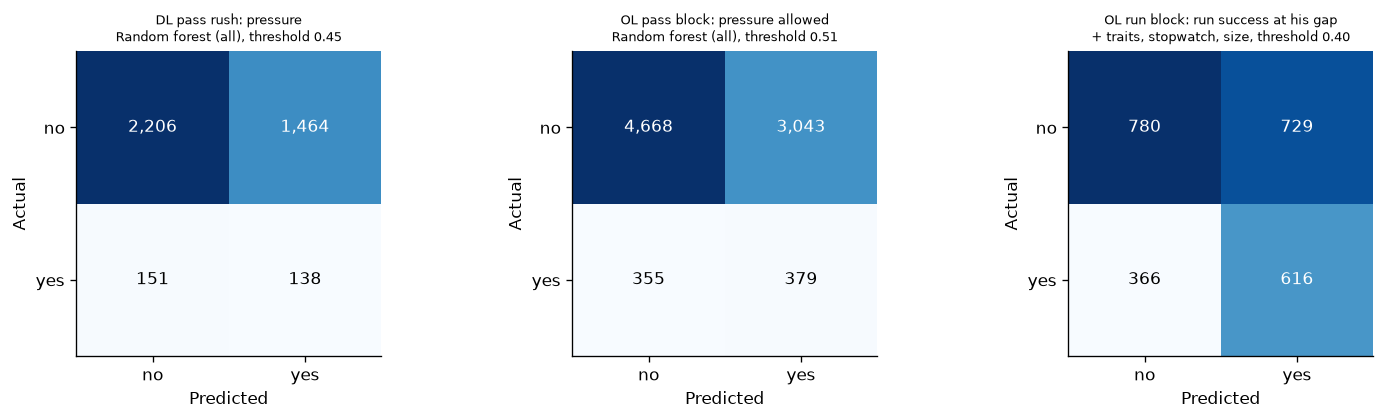

In [9]:
clf_tasks = [t for t in TASKS if FS["tasks"][t]["kind"] == "classification"]
fig, axes = plt.subplots(1, len(clf_tasks), figsize=(4.2 * len(clf_tasks), 3.6))
cm_rows = []
for ax, task in zip(np.atleast_1d(axes), clf_tasks):
    m = champ.loc[task, "model"]; r = res[(res.task == task) & (res.model == m)].iloc[0]
    t = preds[(task, m, "test")]; k = at_thr(t.target.values, t.p.values, r.threshold)
    M = np.array([[k["tn"], k["fp"]], [k["fn"], k["tp"]]]); cm_rows.append({"task": task, "model": m, **k})
    ax.imshow(M, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{M[i, j]:,}", ha="center", va="center", color="white" if M[i, j] > M.max() / 2 else "black")
    ax.set_xticks([0, 1], ["no", "yes"]); ax.set_yticks([0, 1], ["no", "yes"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    ax.set_title(f"{TASK_LABEL[task]}\n{LABEL[m]}, threshold {r.threshold:.2f}", fontsize=8)
pd.DataFrame(cm_rows).to_csv(C.TABLE_DIR / "07_confusion_matrices.csv", index=False)
fig.tight_layout(); fig.savefig(C.FIG_DIR / "07_confusion_matrices.png", bbox_inches="tight"); plt.show()

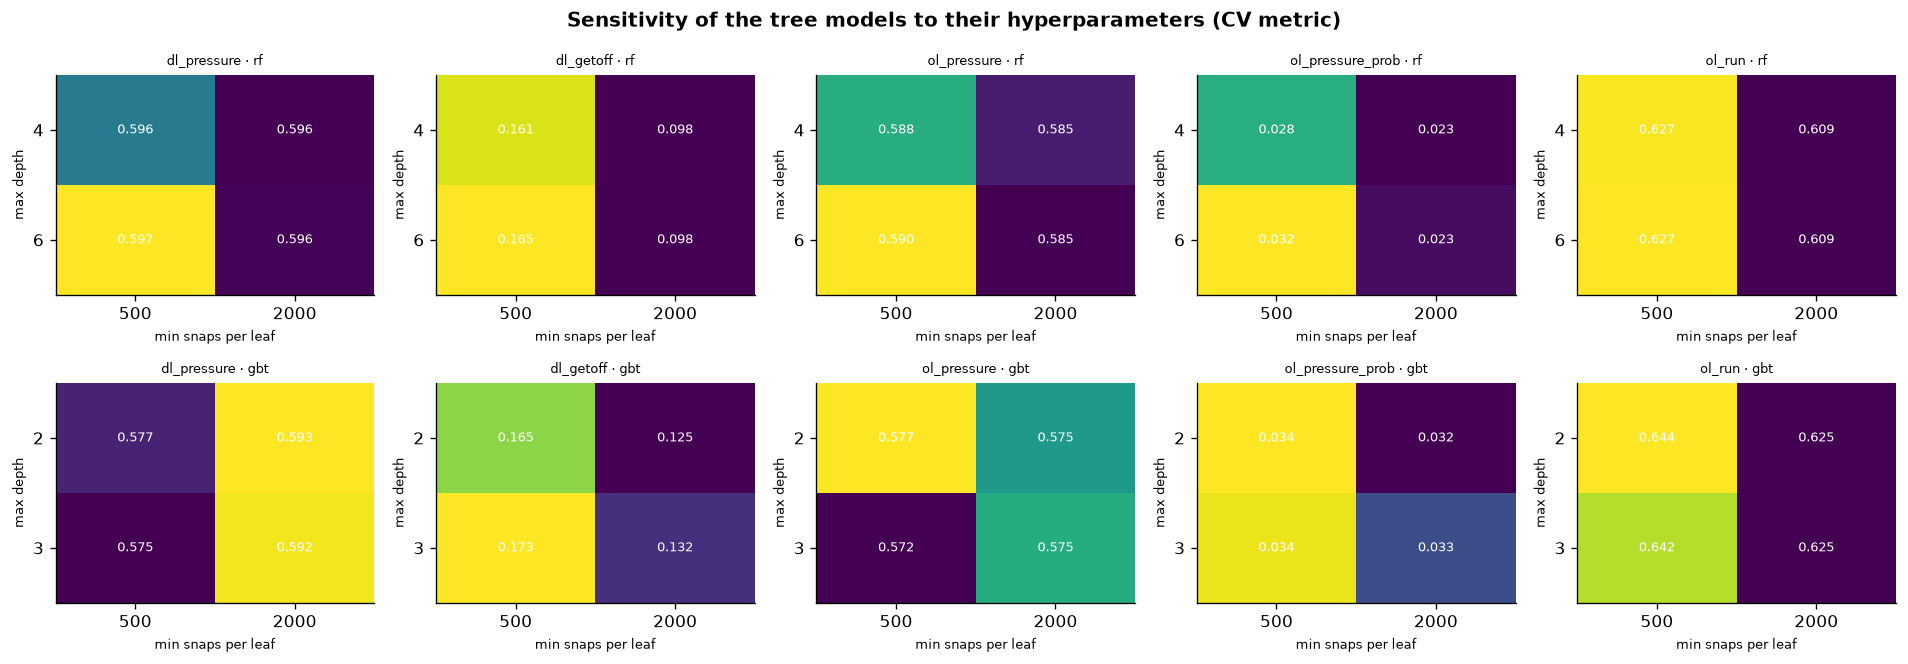

min     max
task             model                      
dl_getoff        benchmark    0.2044  0.2046
                 burst        0.2065  0.2066
                 first_step   0.1889  0.1896
                 gbt          0.1252  0.1731
                 lateral      0.2034  0.2037
                 rf           0.0976  0.1650
                 stopwatch    0.1935  0.1973
                 traits       0.1961  0.1971
                 traits_size  0.1829  0.1918
dl_pressure      benchmark    0.5892  0.5896
                 burst        0.5876  0.5881
                 first_step   0.5898  0.5904
                 gbt          0.5754  0.5926
                 lateral      0.5873  0.5878
                 rf           0.5958  0.5967
                 stopwatch    0.5948  0.5953
                 traits       0.5813  0.5825
                 traits_size  0.5859  0.5890
ol_pressure      benchmark    0.5952  0.5952
                 burst        0.5939  0.5940
                 first_step   0.5943  0.5944
                 gbt          0.5718  0.5774
                 lateral      0.5947  0.5947
                 rf           0.5845  0.5900
                 stopwatch    0.5925  0.5926
                 traits       0.5936  0.5938
                 traits_size  0.5851  0.5866
ol_pressure_prob benchmark    0.0407  0.0409
                 burst        0.0403  0.0405
                 first_step   0.0402  0.0404
                 gbt          0.0323  0.0343
                 lateral      0.0407  0.0408
                 rf           0.0226  0.0319
                 stopwatch    0.0396  0.0401
                 traits       0.0398  0.0401
                 traits_size  0.0376  0.0385
ol_run           benchmark    0.6397  0.6402
                 burst        0.6396  0.6399
                 first_step   0.6399  0.6402
                 gbt          0.6247  0.6440
                 lateral      0.6396  0.6401
                 rf           0.6090  0.6267
                 stopwatch    0.6354  0.6363
                 traits       0.6395  0.6399
                 traits_size  0.6353  0.6364

In [10]:
# Sensitivity: CV metric across the grid of each task's tree models (depth × min snaps per leaf)
fig, axes = plt.subplots(2, len(TASKS), figsize=(3.2 * len(TASKS), 5.6))
for c, task in enumerate(TASKS):
    for r_, m in enumerate(["rf", "gbt"]):
        ax = axes[r_, c]; d = cv_res[(cv_res.task == task) & (cv_res.model == m)]
        hm = d.pivot_table(index="maxDepth", columns="minInstancesPerNode", values="cv_mean")
        if hm.empty:
            ax.axis("off"); continue
        ax.imshow(hm.values, cmap="viridis", aspect="auto")
        for i in range(hm.shape[0]):
            for j in range(hm.shape[1]):
                ax.text(j, i, f"{hm.values[i, j]:.3f}", ha="center", va="center", color="white", fontsize=8)
        ax.set_xticks(range(hm.shape[1]), [f"{v:g}" for v in hm.columns]); ax.set_yticks(range(hm.shape[0]), [f"{v:g}" for v in hm.index])
        ax.set_xlabel("min snaps per leaf", fontsize=8); ax.set_ylabel("max depth", fontsize=8)
        ax.set_title(f"{task} · {m}", fontsize=8)
fig.suptitle("Sensitivity of the tree models to their hyperparameters (CV metric)", fontweight="bold")
fig.tight_layout(); fig.savefig(C.FIG_DIR / "07_sensitivity.png", bbox_inches="tight"); plt.show()
sens = cv_res.groupby(["task", "model"]).cv_mean.agg(["min", "max"]).round(4)
sens.to_csv(C.TABLE_DIR / "07_sensitivity_ranges.csv"); sens

## 5. Feature importance by block (GBT models)

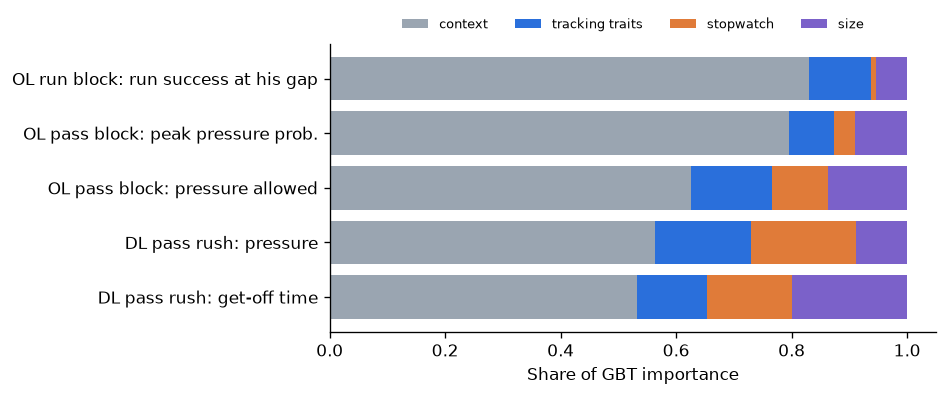

block,context,size,stopwatch,tracking traits
task,,,,
dl_getoff,0.533,0.200,0.147,0.120
dl_pressure,0.563,0.089,0.182,0.167
ol_pressure,0.626,0.137,0.096,0.140
ol_pressure_prob,0.796,0.091,0.035,0.078
ol_run,0.831,0.054,0.008,0.107


In [11]:
def block(n):
    if n.startswith("trk_"): return "tracking traits"
    if n.startswith("sw_") or n.startswith("miss_sw"): return "stopwatch"
    if n in FS["size"]: return "size"
    return "context"
imp_rows = []
for task in TASKS:
    mdl = PipelineModel.load(str(C.MODEL_DIR / task / "gbt"))
    attrs = mdl.transform(data[task].limit(5)).schema["features"].metadata["ml_attr"]["attrs"]
    names = [a["name"] for a in sorted([a for g in attrs.values() for a in g], key=lambda a: a["idx"])]
    imp = mdl.stages[-1].featureImportances.toArray()
    for n_, v in zip(names, imp):
        imp_rows.append({"task": task, "feature": n_, "block": block(n_), "importance": v})
imp = pd.DataFrame(imp_rows); imp.to_csv(C.TABLE_DIR / "07_gbt_feature_importance.csv", index=False)
shares = imp.groupby(["task", "block"]).importance.sum().unstack().fillna(0)
shares = shares.div(shares.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(8, 3.4))
left = np.zeros(len(shares)); bc = {"context": "#9aa5b1", "tracking traits": "#2a6fdb", "stopwatch": "#e07b39", "size": "#7b61c9"}
for b in ["context", "tracking traits", "stopwatch", "size"]:
    if b in shares:
        ax.barh([TASK_LABEL[t] for t in shares.index], shares[b], left=left, color=bc[b], label=b); left += shares[b].values
ax.legend(frameon=False, fontsize=8, ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1.0)); ax.set_xlabel("Share of GBT importance")
fig.tight_layout(); fig.savefig(C.FIG_DIR / "07_importance_blocks.png", bbox_inches="tight"); plt.show()
shares.round(3)

## 6. Player-level ranking of the 2025 rookies
Spearman correlation between a player's mean prediction and his actual average outcome (players with 30+ test snaps).

In [12]:
pr = []
for task in TASKS:
    for m in ["benchmark", "traits", "stopwatch", "traits_size", "gbt", "oracle"]:
        t = preds[(task, m, "test")]
        g = t.groupby("nfl_id").agg(n=("target", "size"), y=("target", "mean"), p=("p", "mean")); g = g[g.n >= 30]
        pr.append({"task": task, "model": m, "players": len(g), "spearman": g.y.rank().corr(g.p.rank())})
pr = pd.DataFrame(pr); pr.round(3).to_csv(C.TABLE_DIR / "07_player_ranking.csv", index=False)
pr.pivot_table(index="model", columns="task", values="spearman").round(3)

task,dl_getoff,dl_pressure,ol_pressure,ol_pressure_prob,ol_run
model,,,,,
benchmark,0.858,0.434,0.337,0.625,0.288
gbt,0.788,0.271,-0.019,0.483,0.151
oracle,0.968,0.947,0.955,0.957,0.923
stopwatch,0.819,0.393,0.334,0.623,0.093
traits,0.863,0.347,0.277,0.641,0.147
traits_size,0.765,0.060,0.169,0.563,-0.237
